# Tox21 Evaluation: compare models without being fooled

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/03_Evaluation/notebooks/TD2_tox21_student.ipynb)

TD1 used eight molecular descriptors to predict an SR-MMP assay class.
Here we compare a small tree, a deep tree and a random forest: does a
better training result also mean better predictions on other compounds?

As in TD1, Active and Inactive refer only to the recorded mitochondrial membrane potential assay result (SR-MMP),
not an overall judgement about human toxicity or safety.

Run the four setup cells in section 1, then focus on the training–validation–test split
in section 2. All code is supplied; write your answers in the Your answer
text cells. Use the standard CPU runtime in Colab.

## 1. Quick recap and setup

Reuse TD1's Tox21 data and eight descriptors. The preparation below
keeps the same 5,804 compounds with readable structures and known targets. Missing assay results
remain unknown and are excluded, along with unreadable structures.

Install the same fixed RDKit version as TD1.

In [1]:
%pip -q install rdkit==2025.9.6

Load the tools for tables, descriptor calculations, plots and models.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
RDLogger.DisableLog("rdApp.*")

Read and clean the same data as TD1. The output checks the retained
record count and shows that Inactive results are more common than Active.

In [3]:
DATA_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz"
raw_data = pd.read_csv(DATA_URL)
data = raw_data.dropna(subset=["SR-MMP", "smiles"]).copy()
data["molecule"] = data["smiles"].map(Chem.MolFromSmiles)
readable = data["molecule"].notna()
print("Structures that could not be read:", (~readable).sum())
data = data.loc[readable].copy()
targets = data["SR-MMP"].map({0: "Inactive", 1: "Active"})
print("Records kept:", len(data))
print(targets.value_counts())

Structures that could not be read: 6
Records kept: 5804
SR-MMP
Inactive    4886
Active       918
Name: count, dtype: int64


Calculate the same eight descriptors and show a feature-table reminder.
The assay target stays separate; the models receive the unrounded values.

`round(2)` displays two digits after the decimal point: for example,
180.157 becomes 180.16. The calculations keep the full precision.

In [4]:
features = pd.DataFrame(index=data.index)
features["Mass"] = data["molecule"].map(Descriptors.MolWt)
features["LogP"] = data["molecule"].map(Descriptors.MolLogP)
features["H_donors"] = data["molecule"].map(Descriptors.NumHDonors)
features["H_acceptors"] = data["molecule"].map(Descriptors.NumHAcceptors)
features["Polar_area"] = data["molecule"].map(Descriptors.TPSA)
features["Rotatable_bonds"] = data["molecule"].map(Descriptors.NumRotatableBonds)
features["Aromatic_rings"] = data["molecule"].map(Descriptors.NumAromaticRings)
features["Heavy_atoms"] = data["molecule"].map(Descriptors.HeavyAtomCount)
features.head().round(2)

,Mass,LogP,H_donors,H_acceptors,Polar_area,Rotatable_bonds,Aromatic_rings,Heavy_atoms
0,258.32,1.34,1,5,82.28,3,2,16
1,204.23,1.30,1,2,49.41,2,1,15
3,276.42,3.75,1,2,32.34,7,1,20
4,206.03,-0.99,5,3,135.29,2,0,11
5,290.44,4.82,0,4,36.92,7,0,20


## 2. Give three sample groups different jobs

- Training: teach each model.
- Validation: compare models and choose one.
- Test: check the fixed choice at the end.

Keep TD1's 1,161 test records aside. Divide its original 4,643 training
records into 3,482 training and 1,161 validation records. Every model uses
the same groups. The small tree now learns from fewer examples than in TD1,
so its results can change.

The code first repeats TD1's split, then divides its original training group.
`X_development` and `y_development` hold that group before it is divided.

In [5]:
X_development, X_test, y_development, y_test = train_test_split(
    features, targets, test_size=0.20, random_state=42, stratify=targets
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25,
    random_state=42, stratify=y_development
)
print("Training:", len(X_train))
print("Validation:", len(X_validation))
print("Test:", len(X_test))

Training: 3482
Validation: 1161
Test: 1161


The test group was already used in Foundations. We exclude it from choosing
models here, but its reuse is a classroom comparison, not fresh independent
evidence. Related chemical families can still occur across groups.

### Stop and explain 1

Which group teaches the models, which helps choose one, and which checks
the choice? Why should all models use the same training and validation records?

Your answer:

Write your answer here in words.

## 3. Compare a small and a deep tree

Start with the same two-question depth limit as Foundations. `fit` teaches
the model; for these classifiers, `score` gives accuracy on the named data.
Accuracy is the fraction of predictions matching the recorded targets.

As in TD1, `class_weight="balanced"` gives each of the rarer Active
compounds more importance while the rules are learned. Both classes then
have equal total training importance. This does not add compounds or change
how accuracy is calculated. Every model below uses this same rule.

An accuracy of 0.90 means that 90% of the samples were classified correctly.

Displayed scores are rounded to three decimal places: for example,
0.87654 is shown as 0.877. This changes the display, not the score used.

In [6]:
small_tree = DecisionTreeClassifier(
    max_depth=2, class_weight="balanced", random_state=42
)
small_tree.fit(X_train, y_train)
small_training = small_tree.score(X_train, y_train)
small_validation = small_tree.score(X_validation, y_validation)
print("Small tree, training:", round(small_training, 3))
print("Small tree, validation:", round(small_validation, 3))

Small tree, training: 0.737
Small tree, validation: 0.748


Remove the depth limit so that the tree can keep adding questions. Only
this setting changes; the data and class-balancing rule stay the same.

Overfitting means learning details that help on training examples but
do not help as much on other examples. A growing gap between training and
validation accuracy is a warning sign.

In [7]:
deep_tree = DecisionTreeClassifier(class_weight="balanced", random_state=42)
deep_tree.fit(X_train, y_train)
deep_training = deep_tree.score(X_train, y_train)
deep_validation = deep_tree.score(X_validation, y_validation)
print("Deep tree, training:", round(deep_training, 3))
print("Deep tree, validation:", round(deep_validation, 3))

Deep tree, training: 0.997
Deep tree, validation: 0.834


### Stop and explain 2

How much does training accuracy improve for the deeper tree? Does validation
accuracy improve by as much? What does the difference suggest about overfitting?

Your answer:

Write your answer here in words.

## 4. Add a random forest

Imagine asking 100 different sorting trees about the same compound.
Each tree learns from a different random collection of training
examples: some examples can be drawn more than once, while others
are left out of that tree. At each decision, the tree considers a
random selection of features and learns a useful cut-off among them.
This gives the trees different sorting routes.

A new compound follows a route through every tree. Each final group
gives an estimate of support for each class. The forest averages
those estimates and predicts the class with the greater support.
A final group dominated by Active training importance gives more support
to Active.

For illustration, suppose three trees give these estimates for one compound:

| Tree | Estimated support for Active |
|---|---|
| 1 | 80% |
| 2 | 60% |
| 3 | 40% |
| Average | 60% |

Together they predict Active. The 60% describes estimated support
for this one compound; validation accuracy describes how often the
forest is correct across many examples with known targets.

One tree's poor decision has less influence when the other trees
make different mistakes. Making 100 identical copies of one tree
would repeat its mistakes. Combining varied trees can help, but we
still need validation to check whether it helps on our data.

The code builds 100 trees, fits them, and checks the same training
and validation groups used by the other models.

In [8]:
forest = RandomForestClassifier(
    n_estimators=100, class_weight="balanced", random_state=42
)
forest.fit(X_train, y_train)
forest_training = forest.score(X_train, y_train)
forest_validation = forest.score(X_validation, y_validation)
print("Forest, training:", round(forest_training, 3))
print("Forest, validation:", round(forest_validation, 3))

Forest, training: 0.995
Forest, validation: 0.867


Put the scores in one table. Look at validation accuracy because those
compounds did not teach any model.

In [9]:
results = pd.DataFrame({
    "Model": ["Small tree", "Deep tree", "Forest"],
    "Training": [small_training, deep_training, forest_training],
    "Validation": [small_validation, deep_validation, forest_validation]
})
results = results.set_index("Model")
results.round(3)

,Training,Validation
Model,,
Small tree,0.737,0.748
Deep tree,0.997,0.834
Forest,0.995,0.867


The bars show the same scores. Compare with the rule that always predicts
Inactive. It can have high accuracy while missing every Active result.
`==` checks whether targets match Inactive; `mean()` gives the matching fraction.

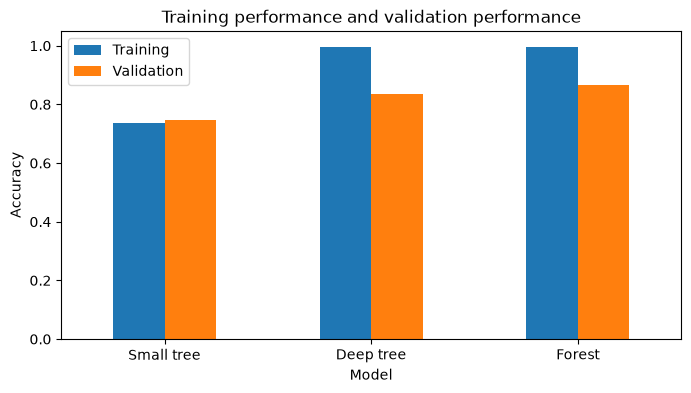

Always Inactive, validation: 0.842


In [10]:
results.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Training performance and validation performance")
plt.show()
baseline_validation = (y_validation == "Inactive").mean()
print("Always Inactive, validation:", round(baseline_validation, 3))

### Stop and explain 3

Which model has the highest validation accuracy? Does it beat always
predicting Inactive? Why must we still inspect missed Active results?
Why are varied trees more useful than 100 identical copies of one tree?

Your answer:

Write your answer here in words.

## 5. Choose first, then test

For this teaching comparison, choose the highest validation accuracy.
`idxmax` returns that model's name; the first line links names to trained
models. `models[chosen_name]` retrieves the chosen model. No model is retrained.
A real screening decision would also consider the costs of both error types.

In [11]:
models = {"Small tree": small_tree, "Deep tree": deep_tree, "Forest": forest}
chosen_name = results["Validation"].idxmax()
chosen_model = models[chosen_name]
print("Chosen using validation samples:", chosen_name)

Chosen using validation samples: Forest


Apply the fixed model to test features. Test targets check the predictions;
they did not choose the model. Keep the choice fixed after viewing results.

In the confusion matrix, rows are recorded targets and columns predictions.
Active predicted Inactive is a missed Active result (false negative);
Inactive predicted Active is a false alarm (false positive).

Test accuracy: 0.878


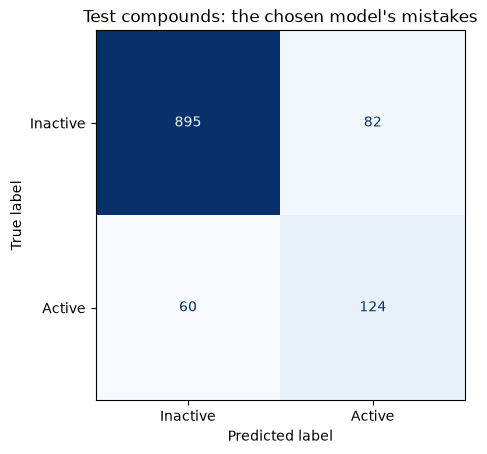

In [12]:
predictions = chosen_model.predict(X_test)
test_accuracy = accuracy_score(y_test, predictions)
print("Test accuracy:", round(test_accuracy, 3))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["Inactive", "Active"],
    cmap="Blues", colorbar=False
)
plt.title("Test compounds: the chosen model's mistakes")
plt.show()

### Stop and explain 4

How many Active results were missed and how many false alarms occurred?
Why would trying more settings now make this test less useful as a final check?

Your answer:

Write your answer here in words.

## 6. See what happens as a tree gets deeper

The model choice and its test check above are finished. Now use a
training/test curve to illustrate overfitting. Each tree below learns
from the same 3,482 training compounds, with a different maximum depth.
All trees keep `class_weight="balanced"`, just as before. Only depth changes.

The loop repeats the same fit-and-check steps for depths 1 to 12 and
records both accuracies. All code is supplied; focus on the two curves.
The inputs remain the same eight molecular descriptors.

In [13]:
depths = range(1, 13)
depth_training = []
depth_test = []
for depth in depths:
    depth_tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=42)
    depth_tree.fit(X_train, y_train)
    depth_training.append(depth_tree.score(X_train, y_train))
    depth_test.append(depth_tree.score(X_test, y_test))

Follow the training and test lines separately. A deeper tree can fit
smaller groups of training compounds. Better training accuracy can
coexist with less improvement, or deterioration, on excluded compounds.
A growing gap is a warning about overfitting.

Some steps can go down even on training data: the tree gives extra
importance to rarer Active compounds while learning, whereas the accuracy
shown here counts every compound equally. Look at the overall pattern.
As before, overall accuracy
should be read alongside the selected model's missed Active results.

This test curve is a classroom illustration after model selection.
Choosing a new depth from its highest point would use test outcomes for
selection. A further independent test would then be needed. Use validation
results to choose depth during model development.

The vertical axis is zoomed to 0.60–1.00 so the differences are easier
to see. Read the accuracy values as well as the distance between the lines.

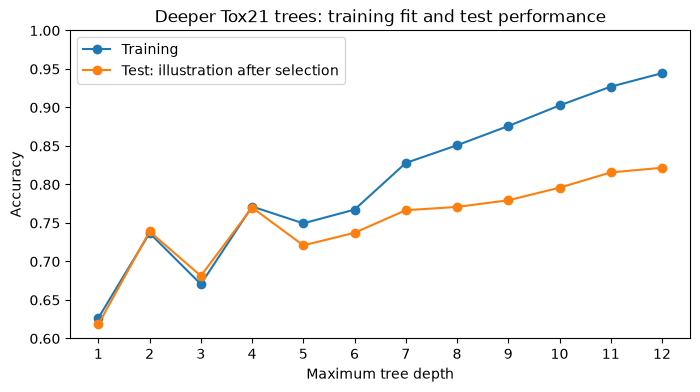

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(depths, depth_training, marker="o", label="Training")
plt.plot(depths, depth_test, marker="o", label="Test: illustration after selection")
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.xticks(depths)
plt.ylim(0.60, 1.00)
plt.title("Deeper Tox21 trees: training fit and test performance")
plt.legend()
plt.show()

### Stop and explain 5

Do training and test accuracy improve together as depth increases?
Use the gap to explain overfitting. If we now chose a depth from the
best test point, what would we need for an independent final check?

Your answer:

Write your answer here in words.

## 7. Explain the comparison

Training teaches, validation chooses, and testing checks the fixed choice.
A training/validation gap warns about overfitting. Neither high accuracy
nor the Inactive target establishes human safety.

Next, Applications keeps the eight features and test group but asks which
descriptor patterns are unusual, instead of predicting assay classes.

### Stop and explain 6

Write three sentences for the laboratory manager: what the comparison
showed, which model was chosen and one limitation of its results.

Your answer:

Write your answer here in words.

## Sources and limits

Tox21 targets describe responses under particular laboratory assay conditions.
Active and Inactive do not establish overall human toxicity or safety.
Related chemical families can occur in both sides of our random split;
new chemical families need independent checks.

- [Tox21 programme and challenge](https://tripod.nih.gov/tox21/challenge/about.jsp).
- [Mitochondrial membrane potential assay](https://pubchem.ncbi.nlm.nih.gov/bioassay/720637).
- [Data background and technical notes](https://github.com/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/datasets/tox21/README.md).

Forest reference: [scikit-learn random forest explanation](https://scikit-learn.org/stable/modules/ensemble.html#random-forests).